# 05. Segmentación híbrida: SynthSeg + método clásico

**Idea**: SynthSeg es mejor en ventrículos pequeños y medianos; el método clásico es mejor en hidrocefalia severa, donde SynthSeg falla.

**Regla de decisión** (no usa al experto):
- **H1, por volumen**: si el volumen estimado por el método clásico es `> UMBRAL_ML`, se usa el clásico; si no, SynthSeg. Se usa el volumen del clásico porque casi no tiene sesgo, mientras que SynthSeg subestima justo los casos grandes.
- **H2, por volumen + detección de falla**: H1, y además si SynthSeg da menos de `FRAC_FALLA` del volumen del clásico (y el clásico supera `MIN_FALLA_ML`), se asume falla de SynthSeg y se usa el clásico.

Salidas en `outputs/figuras_05_hibrido/`.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(ROOT))

import shutil
import time
import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

from src.io import list_scans, load, load_seg
from src.paths import OUTPUTS
import src.clasico as clasico

FIG_DIR = OUTPUTS / "figuras_05_hibrido"
if FIG_DIR.exists():
    shutil.rmtree(FIG_DIR)
FIG_DIR.mkdir(parents=True)

def guardar(nombre, dpi=110):
    plt.savefig(FIG_DIR / f"{nombre}.png", dpi=dpi, bbox_inches="tight")

UMBRAL_ML = 150
FRAC_FALLA = 0.5
MIN_FALLA_ML = 60
FS_VENT = [4, 5, 43, 44]

scans = list_scans()
print(len(scans), "estudios")

45 estudios


## Métricas

In [2]:
def dice(a, b):
    d = a.sum() + b.sum()
    return 2 * (a & b).sum() / d if d else np.nan


def hd95(a, b, zooms):
    if a.sum() == 0 or b.sum() == 0:
        return np.nan
    ba = a & ~ndi.binary_erosion(a)
    bb = b & ~ndi.binary_erosion(b)
    da = ndi.distance_transform_edt(~bb, sampling=zooms)[ba]
    db = ndi.distance_transform_edt(~ba, sampling=zooms)[bb]
    return np.percentile(np.concatenate([da, db]), 95)


def synthseg(s, shape):
    p = s / "segmentation" / "synthseg.nii.gz"
    if not p.exists():
        return None
    a = np.asarray(nib.as_closest_canonical(nib.load(p)).dataobj).astype(int)
    return np.isin(a, FS_VENT) if a.shape == shape else None


def clasico_completo(img, zooms, shape):
    box = clasico.crop_box(img)
    m = np.zeros(shape, bool)
    v, *_ = clasico.segmentar(img[box], zooms)
    m[box] = v
    return m

## Correr SynthSeg y clásico en todos los estudios
Se guardan las métricas de cada modelo base; el híbrido solo elige cuál usar, así que sus métricas salen de esta tabla.

In [3]:
filas = []
for s in scans:
    t0 = time.time()
    img, zooms = load(s / "eT1W_FFE_SVR.nii.gz")
    gt, _ = load_seg(s / "segmentation" / "gt.nii.gz")
    g = gt == 4
    ml = float(np.prod(zooms)) / 1000
    ss = synthseg(s, g.shape)
    if ss is None:
        print(f"{s.parent.name}/{s.name}: sin SynthSeg compatible, se omite")
        continue
    cl = clasico_completo(img, zooms, g.shape)
    fila = {"subject": s.parent.name, "scan": s.name, "vol_gt": g.sum() * ml}
    for n, m in [("SynthSeg", ss), ("Clasico", cl)]:
        fila[f"dice_{n}"] = dice(m, g)
        fila[f"vol_{n}"] = m.sum() * ml
        fila[f"hd95_{n}"] = hd95(m, g, zooms)
    filas.append(fila)
    print(f"{s.parent.name}/{s.name} ({time.time() - t0:.0f}s): SynthSeg {fila['dice_SynthSeg']:.2f} "
          f"({fila['vol_SynthSeg']:.0f} mL) | Clásico {fila['dice_Clasico']:.2f} ({fila['vol_Clasico']:.0f} mL) | experto {fila['vol_gt']:.0f} mL")

base = pd.DataFrame(filas)
base.to_csv(FIG_DIR / "base_synthseg_clasico.csv", index=False)

sub_001/scan_01 (53s): SynthSeg 0.90 (15 mL) | Clásico 0.63 (16 mL) | experto 15 mL
sub_003/scan_01 (49s): SynthSeg 0.98 (68 mL) | Clásico 0.78 (88 mL) | experto 67 mL
sub_004/scan_01 (50s): SynthSeg 0.84 (207 mL) | Clásico 0.91 (298 mL) | experto 279 mL
sub_005/scan_01 (41s): SynthSeg 0.91 (74 mL) | Clásico 0.86 (94 mL) | experto 82 mL
sub_006/scan_01 (57s): SynthSeg 0.56 (118 mL) | Clásico 0.54 (124 mL) | experto 288 mL
sub_007/scan_01 (51s): SynthSeg 0.86 (15 mL) | Clásico 0.32 (20 mL) | experto 15 mL
sub_009/scan_01 (47s): SynthSeg 0.96 (85 mL) | Clásico 0.67 (153 mL) | experto 86 mL
sub_010/scan_01 (31s): SynthSeg 0.87 (135 mL) | Clásico 0.88 (160 mL) | experto 153 mL
sub_011/scan_01 (41s): SynthSeg 0.80 (188 mL) | Clásico 0.00 (5 mL) | experto 268 mL
sub_012/scan_01 (39s): SynthSeg 0.72 (176 mL) | Clásico 0.92 (329 mL) | experto 311 mL
sub_013/scan_01 (38s): SynthSeg 0.89 (9 mL) | Clásico 0.00 (13 mL) | experto 11 mL
sub_015/scan_01 (47s): SynthSeg 0.06 (13 mL) | Clásico 0.88 (46

## Reglas híbridas

In [4]:
def elegir_h1(r, umbral=UMBRAL_ML):
    return "Clasico" if r.vol_Clasico > umbral else "SynthSeg"


def elegir_h2(r, umbral=UMBRAL_ML, frac=FRAC_FALLA, min_falla=MIN_FALLA_ML):
    if r.vol_Clasico > umbral:
        return "Clasico"
    if r.vol_Clasico > min_falla and r.vol_SynthSeg < frac * r.vol_Clasico:
        return "Clasico"
    return "SynthSeg"


def aplicar(df, nombre, regla):
    df = df.copy()
    df[f"elige_{nombre}"] = df.apply(regla, axis=1)
    for met in ["dice", "vol", "hd95"]:
        df[f"{met}_{nombre}"] = [r[f"{met}_{e}"] for (_, r), e in zip(df.iterrows(), df[f"elige_{nombre}"])]
    return df


df = aplicar(base, "H1", elegir_h1)
df = aplicar(df, "H2", elegir_h2)
MODELOS = ["SynthSeg", "Clasico", "H1", "H2"]
for n in MODELOS:
    df[f"err_{n}_%"] = (df[f"vol_{n}"] - df.vol_gt) / df.vol_gt * 100
df["rango"] = pd.cut(df.vol_gt, [0, 30, 150, np.inf], labels=["pequeño (<30)", "mediano (30-150)", "grande (>150)"])
df.to_csv(FIG_DIR / "hibrido_todos.csv", index=False)

print("H1 eligió:", df.elige_H1.value_counts().to_dict())
print("H2 eligió:", df.elige_H2.value_counts().to_dict())

H1 eligió: {'SynthSeg': 33, 'Clasico': 12}
H2 eligió: {'SynthSeg': 32, 'Clasico': 13}


## Resumen por rango

In [5]:
rows = []
for grupo, sub in [("total", df)] + list(df.groupby("rango", observed=True)):
    for n in MODELOS:
        rows.append({"rango": grupo, "modelo": n, "n": len(sub),
                     "dice_media": sub[f"dice_{n}"].mean(), "dice_mediana": sub[f"dice_{n}"].median(),
                     "dice_min": sub[f"dice_{n}"].min(),
                     "err_vol_abs_mediana_%": sub[f"err_{n}_%"].abs().median(),
                     "hd95_mediana_mm": sub[f"hd95_{n}"].median(),
                     "casos_dice<0.5": int((sub[f"dice_{n}"] < 0.5).sum())})
resumen = pd.DataFrame(rows)
resumen.to_csv(FIG_DIR / "resumen_hibrido.csv", index=False)
display(resumen.round(3))
display(resumen.pivot(index="modelo", columns="rango", values="dice_mediana").round(3))

,rango,modelo,n,dice_media,dice_mediana,dice_min,err_vol_abs_mediana_%,hd95_mediana_mm,casos_dice<0.5
0,total,SynthSeg,45,0.849,0.903,0.062,7.998,3.317,2
1,total,Clasico,45,0.669,0.796,0.000,21.239,16.248,10
2,total,H1,45,0.855,0.905,0.197,7.189,5.196,2
3,total,H2,45,0.856,0.905,0.197,7.189,5.196,2
4,pequeño (<30),SynthSeg,14,0.886,0.897,0.741,5.756,2.532,0
5,pequeño (<30),Clasico,14,0.381,0.428,0.000,50.775,30.272,9
6,pequeño (<30),H1,14,0.840,0.897,0.243,5.756,2.532,1
7,pequeño (<30),H2,14,0.840,0.897,0.243,5.756,2.532,1
8,mediano (30-150),SynthSeg,20,0.887,0.952,0.197,5.006,3.317,1
9,mediano (30-150),Clasico,20,0.827,0.861,0.583,13.869,10.839,0


rango,grande (>150),mediano (30-150),pequeño (<30),total
modelo,,,,
Clasico,0.878,0.861,0.428,0.796
H1,0.884,0.924,0.897,0.905
H2,0.884,0.924,0.897,0.905
SynthSeg,0.839,0.952,0.897,0.903


## Sensibilidad al umbral
`UMBRAL_ML` se fijó a priori en 150 mL. Este barrido muestra qué tan estable es el resultado si se mueve; no se usa para elegirlo.

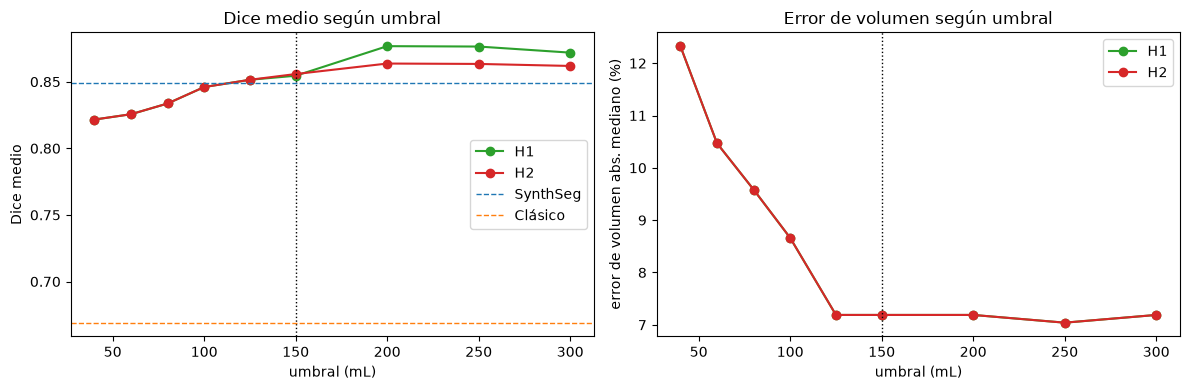

In [6]:
sens = []
for u in [40, 60, 80, 100, 125, 150, 200, 250, 300]:
    for nombre, regla in [("H1", elegir_h1), ("H2", elegir_h2)]:
        el = base.apply(lambda r: regla(r, umbral=u), axis=1)
        d = [r[f"dice_{e}"] for (_, r), e in zip(base.iterrows(), el)]
        v = [r[f"vol_{e}"] for (_, r), e in zip(base.iterrows(), el)]
        err = np.abs((np.array(v) - base.vol_gt) / base.vol_gt * 100)
        sens.append({"umbral_ml": u, "regla": nombre, "dice_media": np.mean(d), "dice_mediana": np.median(d),
                     "err_abs_mediana_%": np.median(err), "casos_dice<0.5": int((np.array(d) < 0.5).sum())})
sens = pd.DataFrame(sens)
sens.to_csv(FIG_DIR / "sensibilidad_umbral.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for nombre, c in [("H1", "tab:green"), ("H2", "tab:red")]:
    s_ = sens[sens.regla == nombre]
    ax[0].plot(s_.umbral_ml, s_.dice_media, "o-", color=c, label=nombre)
    ax[1].plot(s_.umbral_ml, s_["err_abs_mediana_%"], "o-", color=c, label=nombre)
for a, ref in [(ax[0], "dice"), (ax[1], "err")]:
    a.axvline(UMBRAL_ML, color="k", ls=":", lw=1)
    a.set_xlabel("umbral (mL)")
    a.legend()
ax[0].axhline(base.dice_SynthSeg.mean(), color="tab:blue", ls="--", lw=1, label="SynthSeg")
ax[0].axhline(base.dice_Clasico.mean(), color="tab:orange", ls="--", lw=1, label="Clásico")
ax[0].set_ylabel("Dice medio"); ax[0].set_title("Dice medio según umbral"); ax[0].legend()
ax[1].set_ylabel("error de volumen abs. mediano (%)"); ax[1].set_title("Error de volumen según umbral")
plt.tight_layout(); guardar("sensibilidad_umbral"); plt.show()

## Gráficos de comparación

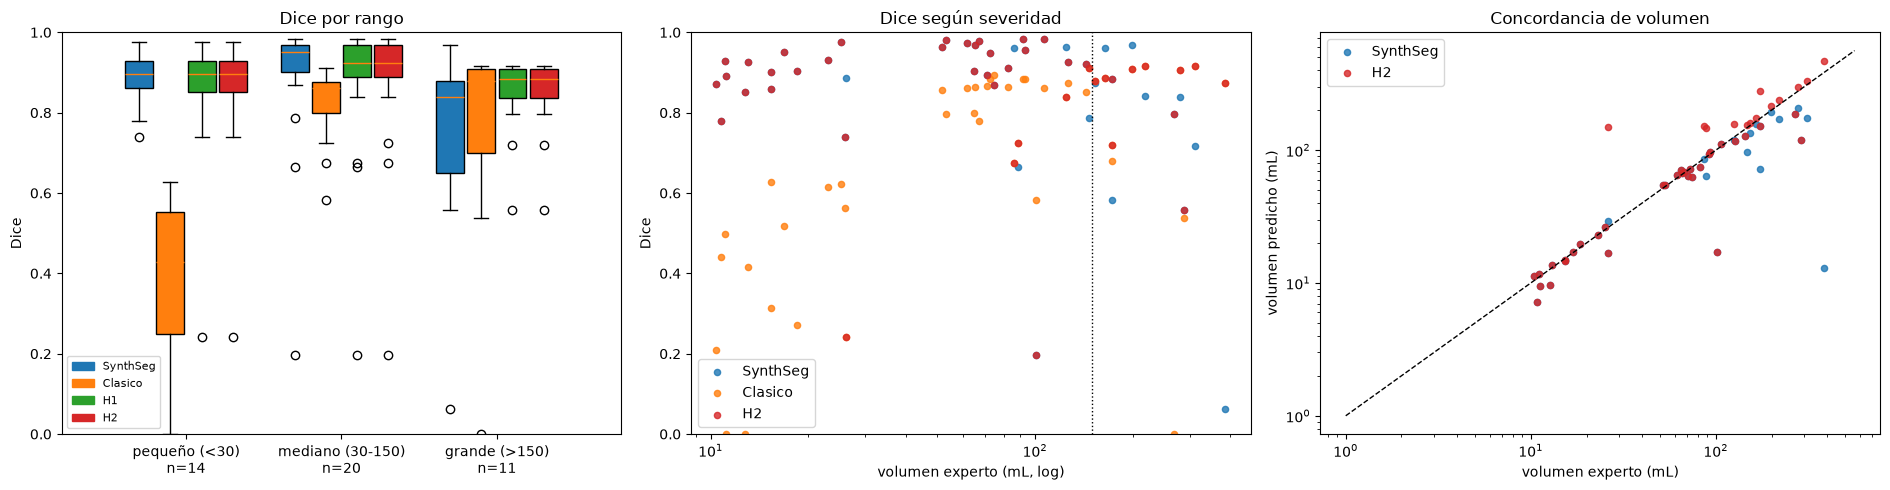

In [7]:
col = {"SynthSeg": "tab:blue", "Clasico": "tab:orange", "H1": "tab:green", "H2": "tab:red"}
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
rangos = list(df.rango.cat.categories)
w = 0.2
for i, n in enumerate(MODELOS):
    pos = np.arange(len(rangos)) + (i - 1.5) * w
    bp = ax[0].boxplot([df.loc[df.rango == r, f"dice_{n}"].dropna() for r in rangos], positions=pos,
                       widths=w * 0.9, patch_artist=True, showfliers=True)
    for b in bp["boxes"]:
        b.set_facecolor(col[n])
ax[0].set_xticks(range(len(rangos)))
ax[0].set_xticklabels([f"{r}\nn={(df.rango == r).sum()}" for r in rangos])
ax[0].set_ylim(0, 1); ax[0].set_ylabel("Dice"); ax[0].set_title("Dice por rango")
ax[0].legend([plt.Rectangle((0, 0), 1, 1, color=col[n]) for n in MODELOS], MODELOS, fontsize=8)

for n in ["SynthSeg", "Clasico", "H2"]:
    ax[1].scatter(df.vol_gt, df[f"dice_{n}"], s=20, color=col[n], label=n, alpha=0.8)
ax[1].axvline(UMBRAL_ML, color="k", ls=":", lw=1)
ax[1].set_xscale("log"); ax[1].set_ylim(0, 1)
ax[1].set_xlabel("volumen experto (mL, log)"); ax[1].set_ylabel("Dice"); ax[1].legend()
ax[1].set_title("Dice según severidad")

lim = [1, df[["vol_gt", "vol_SynthSeg", "vol_Clasico"]].max().max() * 1.2]
for n in ["SynthSeg", "H2"]:
    ax[2].scatter(df.vol_gt, df[f"vol_{n}"], s=20, color=col[n], label=n, alpha=0.8)
ax[2].plot(lim, lim, "k--", lw=1)
ax[2].set_xscale("log"); ax[2].set_yscale("log")
ax[2].set_xlabel("volumen experto (mL)"); ax[2].set_ylabel("volumen predicho (mL)"); ax[2].legend()
ax[2].set_title("Concordancia de volumen")
plt.tight_layout(); guardar("comparacion_hibrido"); plt.show()

## Bland-Altman del volumen

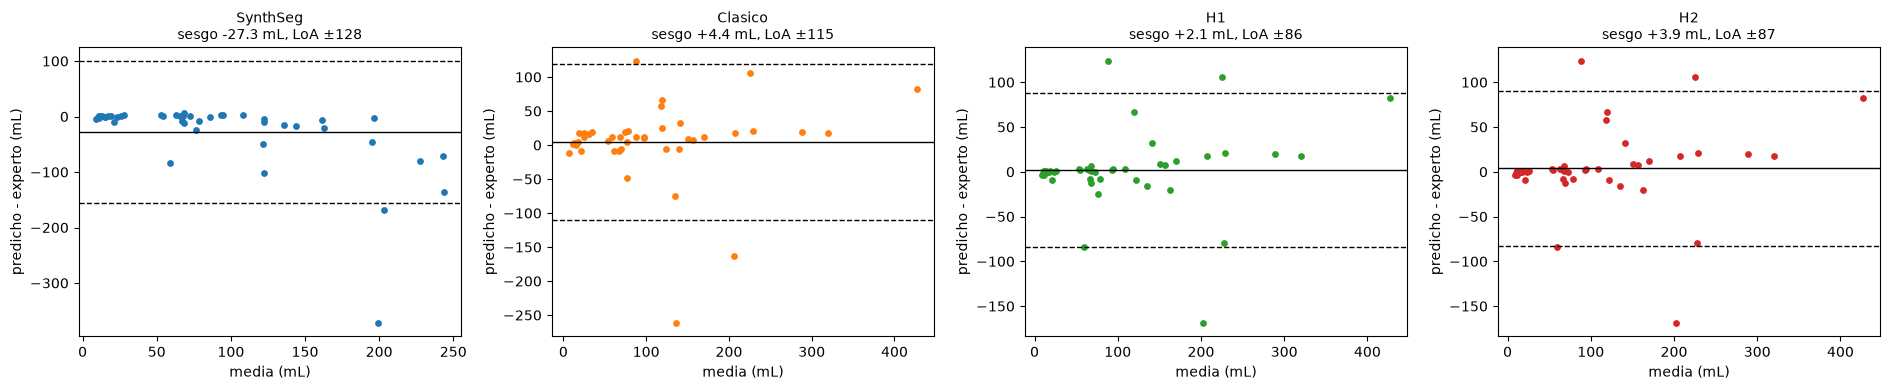

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for a, n in zip(axes, MODELOS):
    m = (df[f"vol_{n}"] + df.vol_gt) / 2
    d = df[f"vol_{n}"] - df.vol_gt
    sesgo, sd = d.mean(), d.std()
    a.scatter(m, d, s=15, color=col[n])
    for y, ls in [(sesgo, "-"), (sesgo + 1.96 * sd, "--"), (sesgo - 1.96 * sd, "--")]:
        a.axhline(y, color="k", ls=ls, lw=1)
    a.set_title(f"{n}\nsesgo {sesgo:+.1f} mL, LoA ±{1.96 * sd:.0f}", fontsize=10)
    a.set_xlabel("media (mL)"); a.set_ylabel("predicho - experto (mL)")
plt.tight_layout(); guardar("bland_altman_hibrido"); plt.show()

## Casos donde el híbrido cambia la decisión

In [9]:
cambios = df[df.elige_H2 == "Clasico"].sort_values("vol_gt")
display(cambios[["subject", "scan", "vol_gt", "vol_SynthSeg", "vol_Clasico", "dice_SynthSeg", "dice_Clasico", "dice_H2"]].round(2))

peores = df.sort_values("dice_H2").head(6)
print("Peores casos del híbrido H2:")
display(peores[["subject", "scan", "elige_H2", "vol_gt", "vol_H2", "dice_SynthSeg", "dice_Clasico", "dice_H2"]].round(2))

,subject,scan,vol_gt,vol_SynthSeg,vol_Clasico,dice_SynthSeg,dice_Clasico,dice_H2
41,sub_045,scan_01,26.08,29.21,150.30,0.89,0.24,0.24
6,sub_009,scan_01,86.20,85.26,152.83,0.96,0.67,0.67
33,sub_038,scan_01,88.88,63.94,146.68,0.67,0.72,0.72
21,sub_024,scan_01,124.69,119.99,156.95,0.96,0.84,0.84
28,sub_032,scan_01,146.87,97.08,155.29,0.79,0.91,0.91
7,sub_010,scan_01,152.60,134.68,160.25,0.87,0.88,0.88
27,sub_031,scan_01,164.04,158.32,175.80,0.96,0.89,0.89
37,sub_041,scan_01,173.15,71.71,278.48,0.58,0.72,0.72
43,sub_047,scan_01,198.38,195.20,215.57,0.97,0.91,0.91
13,sub_017,scan_01,218.28,171.51,239.21,0.84,0.92,0.92


Peores casos del híbrido H2:


,subject,scan,elige_H2,vol_gt,vol_H2,dice_SynthSeg,dice_Clasico,dice_H2
19,sub_022,scan_01,SynthSeg,100.77,17.05,0.20,0.58,0.20
41,sub_045,scan_01,Clasico,26.08,150.30,0.89,0.24,0.24
4,sub_006,scan_01,SynthSeg,287.59,118.36,0.56,0.54,0.56
6,sub_009,scan_01,Clasico,86.20,152.83,0.96,0.67,0.67
37,sub_041,scan_01,Clasico,173.15,278.48,0.58,0.72,0.72
33,sub_038,scan_01,Clasico,88.88,146.68,0.67,0.72,0.72


## Visualización: 6 casos del más pequeño al más grande

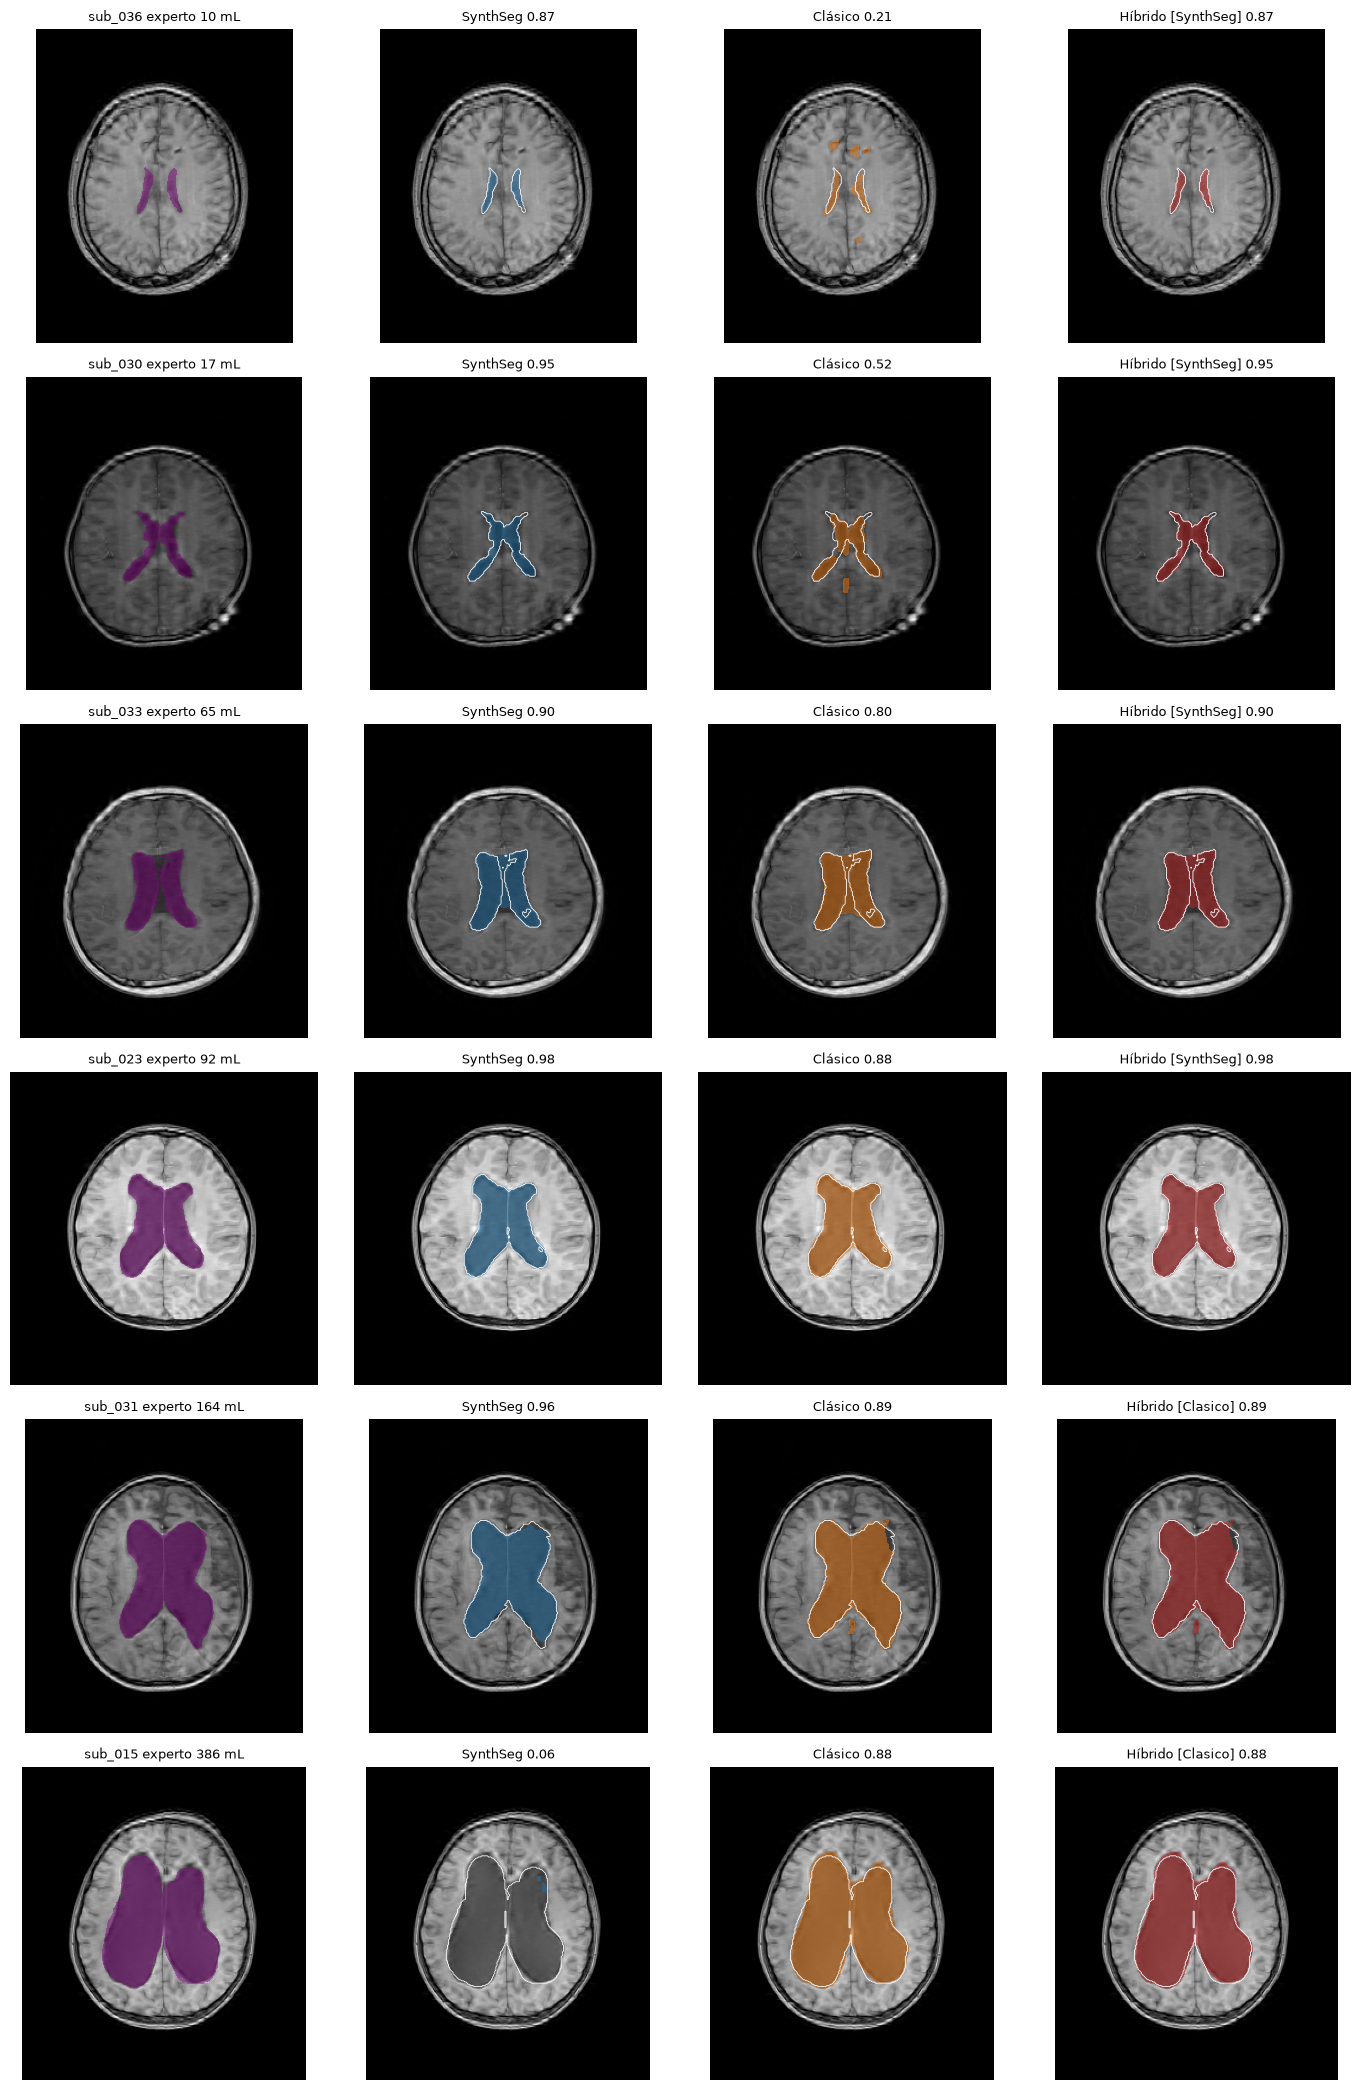

Archivos en C:\Users\Usuario\Desktop\Vida_Academica\2026-II\FIB\hykid\outputs\figuras_05_hibrido
  base_synthseg_clasico.csv
  bland_altman_hibrido.png
  comparacion_hibrido.png
  hibrido_todos.csv
  resumen_hibrido.csv
  sensibilidad_umbral.csv
  sensibilidad_umbral.png
  visual_hibrido.png


In [10]:
orden = df.sort_values("vol_gt")
picks = orden.iloc[np.linspace(0, len(orden) - 1, min(6, len(orden))).astype(int)]
fig, axes = plt.subplots(len(picks), 4, figsize=(14, 3.5 * len(picks)), squeeze=False)
for row, (_, r) in zip(axes, picks.iterrows()):
    s = next(x for x in scans if x.parent.name == r.subject and x.name == r.scan)
    img, zooms = load(s / "eT1W_FFE_SVR.nii.gz")
    g = load_seg(s / "segmentation" / "gt.nii.gz")[0] == 4
    ss = synthseg(s, g.shape)
    cl = clasico_completo(img, zooms, g.shape)
    h2 = cl if r.elige_H2 == "Clasico" else ss
    k = int(np.argmax(g.sum(axis=(0, 1))))
    sl = lambda a: np.rot90(a[:, :, k])
    paneles = [(g, f"{r.subject} experto {r.vol_gt:.0f} mL", "purple"),
               (ss, f"SynthSeg {r.dice_SynthSeg:.2f}", col["SynthSeg"]),
               (cl, f"Clásico {r.dice_Clasico:.2f}", col["Clasico"]),
               (h2, f"Híbrido [{r.elige_H2}] {r.dice_H2:.2f}", col["H2"])]
    for a, (m, t, c) in zip(row, paneles):
        a.imshow(sl(img), cmap="gray")
        a.contourf(sl(m), levels=[0.5, 1.5], colors=[c], alpha=0.45)
        if not t.startswith("sub"):
            a.contour(sl(g), levels=[0.5], colors="white", linewidths=0.6)
        a.set_title(t, fontsize=9)
        a.axis("off")
plt.tight_layout(); guardar("visual_hibrido"); plt.show()
print("Archivos en", FIG_DIR)
for f in sorted(FIG_DIR.iterdir()):
    print(" ", f.name)